<a href="https://colab.research.google.com/github/blood097/Scientific_materials/blob/main/YOLO-learning/YOLOv26_cell.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q "ultralytics>=8.4.0" supervision roboflow
%pip install roboflow

!yolo settings sync=False
from roboflow import Roboflow
from ultralytics import YOLO
import torch
from IPython.display import Image as IPyImage

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.2/280.2 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 276.9/276.9 kB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 92.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 143.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 11.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstar

In [ ]:
print("Доступен ли GPU:", torch.cuda.is_available())
print("Имя GPU:", torch.cuda.get_device_name(0))

Доступен ли GPU: True
Имя GPU: Tesla T4


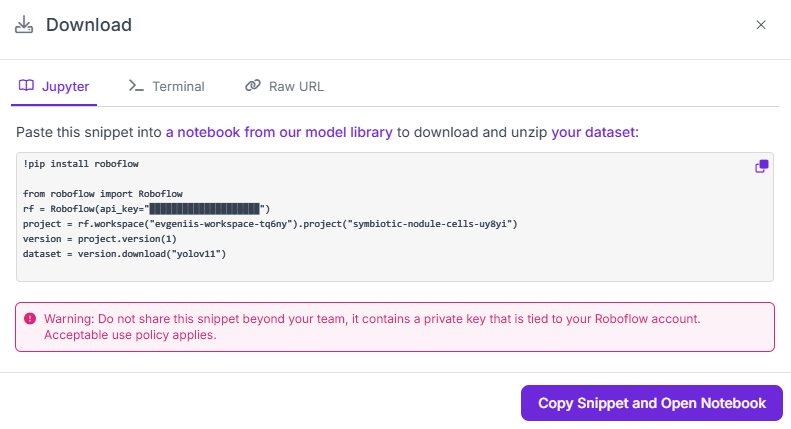

In [ ]:
rf = Roboflow(api_key="**********")
project = rf.workspace("evgeniis-workspace-tq6ny").project("symbiotic-nodule-occupancy")
dataset = project.version(1).download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Symbiotic-nodule-occupancy-1 in yolo26:: 100%|██████████| 359/359 [00:00<00:00, 5426.81it/s]


In [ ]:
model_cell_26 = YOLO("yolo26l-seg.pt")

train_results = model_cell_26.train(data="/content/Symbiotic-nodule-occupancy-1/data.yaml",
                                    epochs=100,
                                    imgsz=640,
                                    plots=True,
                                    task='segment',
                                    device=0)

Ultralytics 8.4.91 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Symbiotic-nodule-occupancy-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimiz

In [ ]:
metrics_26 = model_cell_26.val()

Ultralytics 8.4.91 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26l-seg summary (fused): 207 layers, 27,904,527 parameters, 0 gradients, 139.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1338.9±163.6 MB/s, size: 47.6 KB)
val: Scanning /content/Symbiotic-nodule-occupancy-1/valid/labels.cache... 11 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 11/11 2.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.1it/s 0.9s
                   all         11        272      0.943      0.938      0.973      0.916      0.951      0.945      0.979      0.919
Speed: 0.4ms preprocess, 54.1ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/segment/val


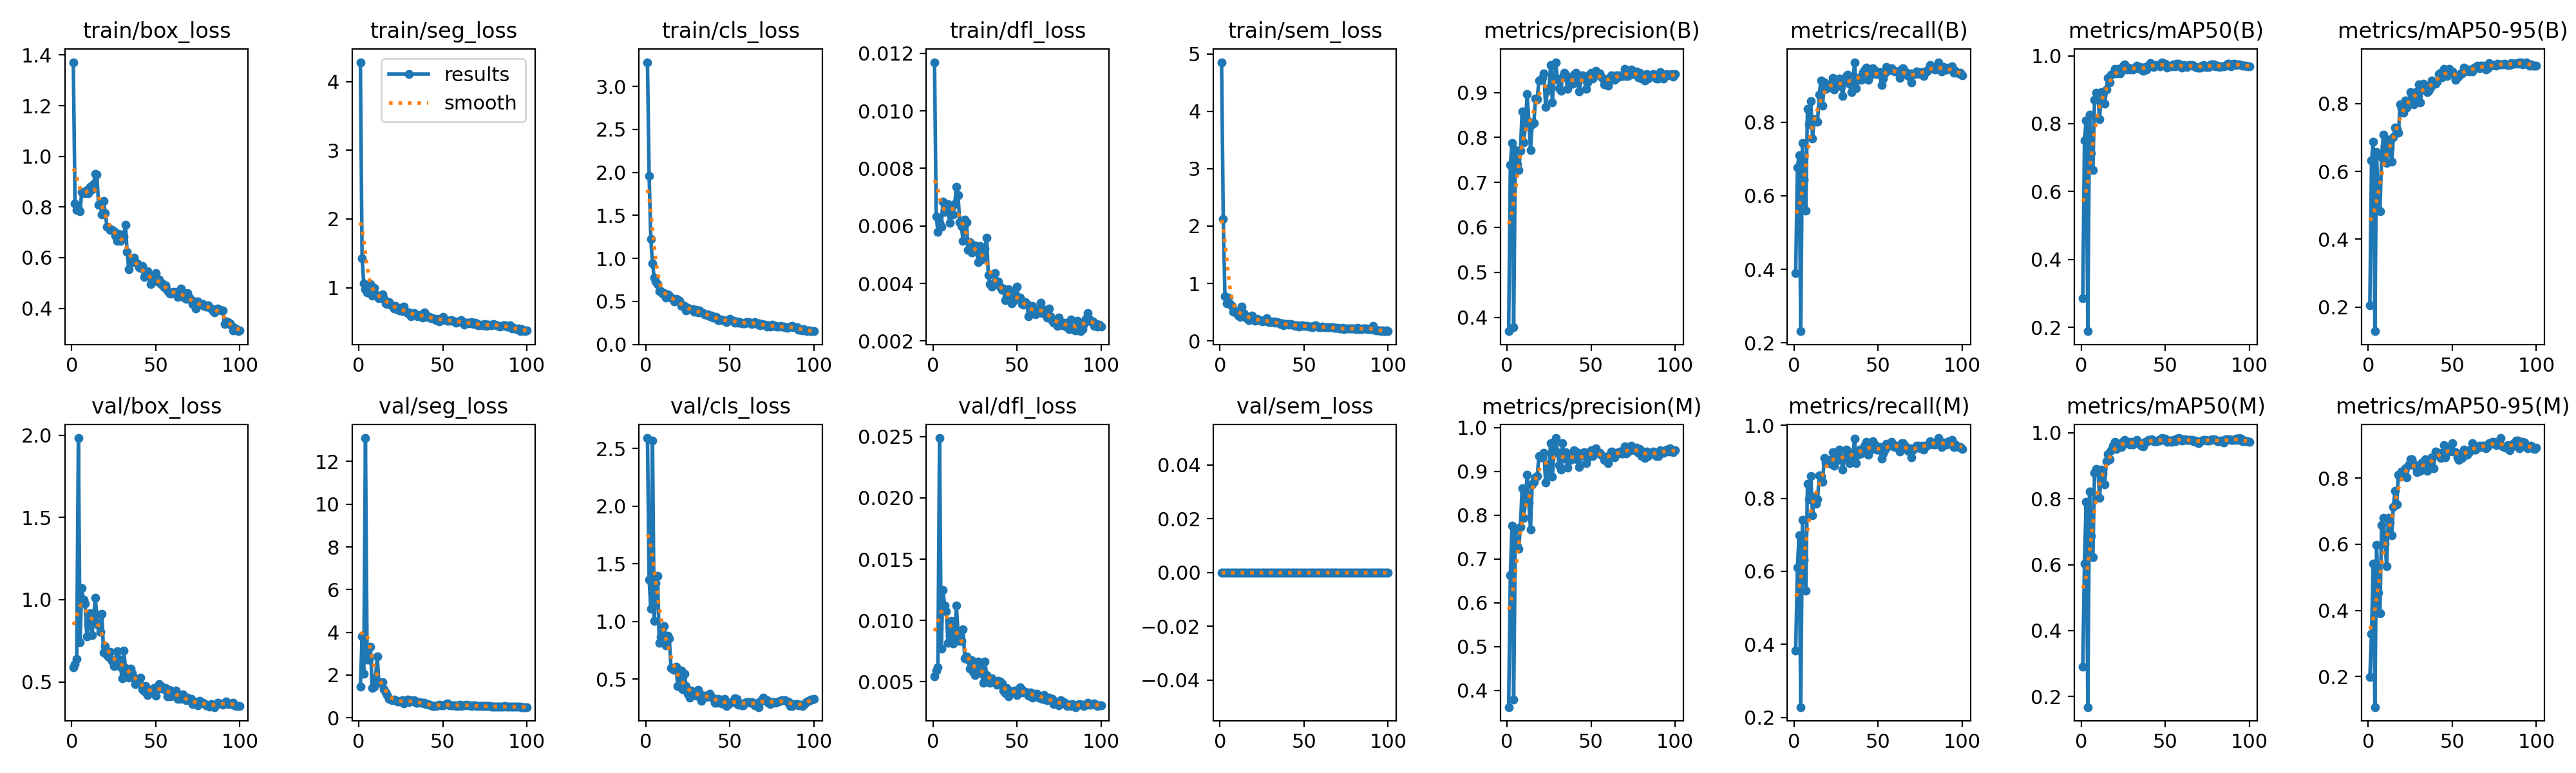

In [ ]:
IPyImage(filename=f'{'./runs/segment/train/results.png'}')